### Amazon_Fashion으로 데이터셋 선정

In [2]:
import gzip
import json
import pandas as pd

file_path = "meta_Amazon_Fashion.jsonl.gz"

items = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for _ in range(5):
        line = f.readline()
        if not line:
            break
        items.append(json.loads(line))

df_preview = pd.DataFrame(items)
df_preview

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,AMAZON FASHION,YUEDGE 5 Pairs Men's Moisture Control Cushione...,4.6,16,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],GiveGift,[],{'Package Dimensions': '10.31 x 8.5 x 1.73 inc...,B08BHN9PK5,None
1,AMAZON FASHION,DouBCQ Women's Palazzo Lounge Wide Leg Casual ...,4.1,7,"[Drawstring closure, Machine Wash]",[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],DouBCQ,[],{'Package Dimensions': '15 x 10.2 x 0.4 inches...,B08R39MRDW,None
2,AMAZON FASHION,Pastel by Vivienne Honey Vanilla Girls' Trapez...,4.3,11,"[Zipper closure, Hand Wash Only]",[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Pastel by Vivienne,[],"{'Is Discontinued By Manufacturer': 'No', 'Pac...",B077KJHCJ4,None
3,AMAZON FASHION,Mento Streamtail,2.0,1,"[Thermoplastic Rubber sole, High Density Premi...",[Slip on the Women's Mento and you're ready to...,29.81,[{'thumb': 'https://m.media-amazon.com/images/...,[],Guy Harvey,[],{'Package Dimensions': '11.22 x 4.72 x 4.33 in...,B0811M2JG9,None
4,AMAZON FASHION,RONNOX Women's 3-Pairs Bright Colored Calf Com...,4.3,3032,"[Pull On closure, Size Guide: ""S"" fits calf 10...",[Ronnox Calf Sleeves - Allowing Your Body to P...,17.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'HONEST Review: RONNOX Women's 3-Pa...,RONNOX,[],"{'Is Discontinued By Manufacturer': 'No', 'Pac...",B07SB2892S,None


In [3]:
df_preview[["parent_asin", "title", "categories"]]

,parent_asin,title,categories
0,B08BHN9PK5,YUEDGE 5 Pairs Men's Moisture Control Cushione...,[]
1,B08R39MRDW,DouBCQ Women's Palazzo Lounge Wide Leg Casual ...,[]
2,B077KJHCJ4,Pastel by Vivienne Honey Vanilla Girls' Trapez...,[]
3,B0811M2JG9,Mento Streamtail,[]
4,B07SB2892S,RONNOX Women's 3-Pairs Bright Colored Calf Com...,[]


In [4]:
print(json.dumps(items[0], indent=2, ensure_ascii=False))

{
  "main_category": "AMAZON FASHION",
  "title": "YUEDGE 5 Pairs Men's Moisture Control Cushioned Dry Fit Casual Athletic Crew Socks for Men (Blue, Size 9-12)",
  "average_rating": 4.6,
  "rating_number": 16,
  "features": [],
  "description": [],
  "price": null,
  "images": [
    {
      "thumb": "https://m.media-amazon.com/images/I/41+cCfaVOFS._AC_SR38,50_.jpg",
      "large": "https://m.media-amazon.com/images/I/41+cCfaVOFS._AC_.jpg",
      "variant": "MAIN",
      "hi_res": "https://m.media-amazon.com/images/I/81XlFXImFrS._AC_UL1500_.jpg"
    },
    {
      "thumb": "https://m.media-amazon.com/images/I/41jBdP7etRS._AC_SR38,50_.jpg",
      "large": "https://m.media-amazon.com/images/I/41jBdP7etRS._AC_.jpg",
      "variant": "PT01",
      "hi_res": "https://m.media-amazon.com/images/I/61+yVkHHQ3S._AC_UL1200_.jpg"
    },
    {
      "thumb": "https://m.media-amazon.com/images/I/41UGJiRe7UL._AC_SR38,50_.jpg",
      "large": "https://m.media-amazon.com/images/I/41UGJiRe7UL._AC_.jpg",


### category가 있는 상품 수 확인

In [7]:
total = 0
has_categories = 0
category_examples = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        item = json.loads(line)
        total += 1

        if item.get("categories"):
            has_categories += 1

            if len(category_examples) < 5:
                category_examples.append({
                    "title": item.get("title"),
                    "categories": item["categories"]
                })

print("전체 상품 수:", total)
print("categories가 있는 상품 수:", has_categories)
print(f"비율: {has_categories / total:.2%}" if total else "파일이 비어 있음")

pd.DataFrame(category_examples)

전체 상품 수: 826108
categories가 있는 상품 수: 0
비율: 0.00%


""


In [8]:
import re

# 운동화 후보를 찾는 조건
pattern = re.compile(r"\b(?:sneakers?|running shoes?)\b", re.IGNORECASE)

shoe_candidates = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        item = json.loads(line)
        title = item.get("title") or ""

        if pattern.search(title):
            shoe_candidates.append({
                "parent_asin": item.get("parent_asin"),
                "title": title
            })

df_shoes = pd.DataFrame(
    shoe_candidates,
    columns=["parent_asin", "title"]
).drop_duplicates(subset="parent_asin")

print("운동화 후보 상품 수:", len(df_shoes))

# 상품명이 잘리지 않게 표시
with pd.option_context("display.max_colwidth", None):
    display(df_shoes.head(30))

운동화 후보 상품 수: 8126


,parent_asin,title
0,B0735L4WTB,"Boys Girls High Top Light Up Shoes Kids Comfortable Fashion Sneakers With LED Lights Grow Up Sole Bottom, Gold"
1,B01LW2POPN,"COODO Toddler Kid's Sneakers Boys Girls Cute Casual Running Shoes (8 Toddler,Black White)"
2,B010DEFYS0,[GGT Tiger] Unisex High Top Sneakers Elastic ROUND Rubber Shoelaces_White
3,B01G5YSV9G,Nike Kids Shox Current (GS) Running Shoes-Wolf Grey/Hyper Pink-6
4,B01M0X7RUK,KOLHIT Kids Light-Up Shoes Boys Girls Winged LED Color Changing Metallic Flashing Sneakers
5,B013FFXZV2,UGG Kids Girl's Hi Top Geometric (Little Kid/Big Kid) Black Sneaker 7 Big Kid M
6,B07CW3GWHR,Under Armour Kids' Grade School Pursuit Graphic Sneaker
7,B085DDBCFH,"LB LAWBUCE Toddler Little Girls High Top Sneaker Casual Canvas Shoes (White, Numeric_3)"
8,B09LLS1LGH,"OrthoComfoot Men's Plantar Fasciitis Slip-Ons Sneakers, Arch Support Walking Loafers, Foot and Heel Pain Relief Arch Support Shoes, Orthopedic Comfortable Casual Slip On"
9,B08Q3KSTT1,UOVO Boys Shoes Boys Sneakers Boys Tennis Running Shoes Waterproof Hiking Shoes Kids Athletic Outdoor Sneakers Slip Resistant(Little/Big Boys) Gray/Green


In [9]:
exclude_pattern = (
    r"\b(?:shoelaces?|shoe\s+laces?|shoestrings?|"
    r"insoles?|shoe\s+inserts?|shoe\s+charms?|"
    r"shoe\s+cleaners?|shoe\s+bags?)\b"
)

is_accessory = df_shoes["title"].str.contains(
    exclude_pattern,
    case=False,
    regex=True,
    na=False
)

df_shoes_clean = df_shoes.loc[~is_accessory].copy()

print("기존 후보:", len(df_shoes))
print("제외한 상품:", is_accessory.sum())
print("남은 후보:", len(df_shoes_clean))

with pd.option_context("display.max_colwidth", None):
    display(
        df_shoes_clean.sample(
            n=min(30, len(df_shoes_clean)),
            random_state=42
        )
    )

기존 후보: 8126
제외한 상품: 445
남은 후보: 7681


,parent_asin,title
6370,B01CR93O0O,"Delight 82 Canvas Lace Up Flat Slip On Boat Comfy Round Toe Sneaker Tennis Shoe, Fucshia, 7"
4739,B01MU9OSOQ,ditont LED Light Up Shoes Remote Control 16 Colors Flashing Sneakers for Kids Boys Girls(DT333Black30)
1683,B078885ZDM,"Blue Berry EASY21 Baby Toddler Boys and Girls Breathable Fashion Sneakers,Fuchsia509,Size 8"
5081,B07D6DND1L,Blockwhales Reusable Shoe Covers Waterproof Latex | One size fits all - Slip Resistant Rubber like Protector from Rain and Dust for Sneakers and Boots
3762,B0788918Y3,"Blue Berry EASY21 Baby Toddler Boys and Girls Breathable Fashion Sneakers,Black507,Size 5"
1277,B01D81MOM4,"Voberry Baby Boys Girls Tassel Bow Soft Sole PU Leather Loafers Moccasin Sneakers (Hot Pink, 6~12 Month)"
5003,B07BZNN4LH,GUBARUN Boys and Girls Lightweight Comfortable Walking Sneakers Kids Running Shoes
4339,B07GKR762F,Yifen Women Girls Cotton Rich Non-slip Low Cut Invisible Socks for Boat Shoes Sneakers Loafers US5-7.5 10Pack (Solid color 10pack)
41,B079DGH753,Merrell Women's Zoe Sojourn Lace Knit Q2 Sneaker
1500,B07T86DY1X,"Goldbug Girls Comfy Slip-on Character Canvas Sneakers Shoes - Glitter & Faux Leather (6-9 Months, Pink)"


In [10]:
extra_accessory = df_shoes_clean["title"].str.contains(
    r"\b(?:socks?|shoe\s+covers?)\b",
    case=False,
    regex=True,
    na=False
)

df_shoes_clean = df_shoes_clean.loc[~extra_accessory].copy()

print("추가 제외:", extra_accessory.sum())
print("최종 후보 상품 수:", len(df_shoes_clean))

추가 제외: 179
최종 후보 상품 수: 7502


In [11]:
review_path = "Amazon_Fashion.jsonl.gz"

selected_ids = set(df_shoes_clean["parent_asin"].dropna())

matched_count = 0
nonempty_count = 0
products_with_reviews = set()

with gzip.open(review_path, "rt", encoding="utf-8") as f:
    for line in f:
        review = json.loads(line)
        product_id = review.get("parent_asin")

        if product_id in selected_ids:
            matched_count += 1
            products_with_reviews.add(product_id)

            text = review.get("text") or ""
            if text.strip():
                nonempty_count += 1

print("선별한 상품 수:", len(selected_ids))
print("실제로 리뷰가 연결된 상품 수:", len(products_with_reviews))
print("연결된 전체 리뷰 수:", matched_count)
print("그중 본문이 비어 있지 않은 리뷰 수:", nonempty_count)

선별한 상품 수: 7502
실제로 리뷰가 연결된 상품 수: 7501
연결된 전체 리뷰 수: 14212
그중 본문이 비어 있지 않은 리뷰 수: 14208


In [12]:
review_rows = []

with gzip.open(review_path, "rt", encoding="utf-8") as f:
    for line in f:
        review = json.loads(line)
        text = review.get("text") or ""

        if (
            review.get("parent_asin") in selected_ids
            and text.strip()
        ):
            review_rows.append({
                "parent_asin": review.get("parent_asin"),
                "user_id": review.get("user_id"),
                "title": review.get("title"),
                "text": text,
                "rating": review.get("rating")
            })

df_reviews = pd.DataFrame(review_rows)

print("추출한 리뷰 수:", len(df_reviews))
display(df_reviews.head())

추출한 리뷰 수: 14208


,parent_asin,user_id,title,text,rating
0,B07MBY27VS,AFZUK3MTBIBEDQOPAK3OATUOUKLA,UOVO boys shoes,8 year old grandson with a fairly regular/norm...,4.0
1,B082363DFL,AHV6QCNBJNSGLATP56JAWJ3C4G2A,Impressive!,This shoe protector is impressive! It's magica...,5.0
2,B09WL4GSH9,AHV6QCNBJNSGLATP56JAWJ3C4G2A,Nicely Cushioned,These kids athletic shoes are nicely cushioned...,5.0
3,B00QH4IQ4A,AHV6QCNBJNSGLATP56JAWJ3C4G2A,The soles are pretty thick. The cat image is n...,Photos don't do these shoes justice. I was imp...,5.0
4,B082363DFL,AFJBKPK5W56XWSNPQU2WW66ISWYQ,Works great,Great product. Works great on a pair of white ...,5.0


In [13]:
print("별점별 리뷰 수")
print(df_reviews["rating"].value_counts().sort_index())

print("\n상품·작성자·본문·별점이 모두 같은 중복 행 수")
print(
    df_reviews.duplicated(
        subset=["parent_asin", "user_id", "text", "rating"]
    ).sum()
)

별점별 리뷰 수
rating
1.0    2002
2.0    1100
3.0    1357
4.0    1968
5.0    7781
Name: count, dtype: int64

상품·작성자·본문·별점이 모두 같은 중복 행 수
159


In [14]:
df_reviews = df_reviews.drop_duplicates(
    subset=["parent_asin", "user_id", "text", "rating"]
).reset_index(drop=True)

print("중복 제거 후 리뷰 수:", len(df_reviews))

중복 제거 후 리뷰 수: 14049


## train/test를 먼저 나누기

In [16]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = df_reviews.drop_duplicates(
    subset=["parent_asin", "user_id", "text", "rating"]
).copy()

df = df[
    df["rating"].isin([1, 2, 3, 4, 5])
    & df["text"].fillna("").str.strip().ne("")
].reset_index(drop=True)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["parent_asin"])
)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

print("Train 리뷰 수:", len(train_df))
print("Test 리뷰 수:", len(test_df))

Train 리뷰 수: 11321
Test 리뷰 수: 2728


## 리뷰 제목과 본문을 합치고, 최소한의 정리하기

In [18]:
import re
import html

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)  # HTML 태그 제거
    text = re.sub(r"\s+", " ", text)     # 연속 공백 정리
    return text.strip()

def combine_text(row):
    title = clean_text(row["title"]) if pd.notna(row["title"]) else ""
    body = clean_text(row["text"]) if pd.notna(row["text"]) else ""

    return f"{title}. {body}" if title else body

train_df["review_text"] = train_df.apply(combine_text, axis=1)
test_df["review_text"] = test_df.apply(combine_text, axis=1)

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from umap import UMAP

print(np.__version__)  # 1.26.4
print("Matplotlib / UMAP import OK")

1.26.4
Matplotlib / UMAP import OK


### 기존과 같은 원본 파일 경로 설정

In [2]:
import gzip
import json
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

# 네 기존 노트북에서 정상 작동한 두 파일명
file_path = Path("meta_Amazon_Fashion.jsonl.gz")
review_path = Path("Amazon_Fashion.jsonl.gz")

for path in (file_path, review_path):
    print(path.resolve(), "| 존재 여부:", path.is_file())
    if not path.is_file():
        raise FileNotFoundError(path.resolve())


def read_jsonl_gz(path):
    """압축을 풀어 별도로 저장하지 않고 JSON 객체를 한 줄씩 읽는다."""
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            yield json.loads(line)

D:\1. 연구, 프로젝트\3. 비정형 term project\meta_Amazon_Fashion.jsonl.gz | 존재 여부: True
D:\1. 연구, 프로젝트\3. 비정형 term project\Amazon_Fashion.jsonl.gz | 존재 여부: True


In [4]:
file_path = Path(r"meta_Amazon_Fashion.jsonl.gz")
review_path = Path(r"Amazon_Fashion.jsonl.gz")

### 운동화에서 신발 전체로 선별 범위 확장

In [6]:
# 줄바꿈과 |를 구분자로 사용해 키워드 목록을 만든다.
def keyword_list(text):
    return [word.strip() for word in re.split(r"[|\n]", text) if word.strip()]


shoe_keywords = keyword_list("""
shoe|shoes|footwear|sneaker|sneakers|cleat|cleats
boot|boots|sandal|sandals|flip flop|flip flops|flip-flop|flip-flops
slipper|slippers|oxfords|derbies|brogues|monk strap|monk straps
loafer|loafers|moccasin|moccasins|high heels|ballet flats|mary janes
clog|clogs|espadrille|espadrilles
""")

exclude_keywords = keyword_list("""
shoelace|shoelaces|shoe lace|shoe laces|shoestring|shoestrings
boot lace|boot laces|replacement laces
insole|insoles|shoe insert|shoe inserts|heel insert|heel inserts
orthotic|orthotics|orthotic insert|orthotic inserts|arch support|arch supports
footbed insert|gel insert|gel inserts
heel pad|heel pads|heel cushion|heel cushions|heel grip|heel grips
shoe pad|shoe pads|foot pad|foot pads|metatarsal pad|metatarsal pads
toe pad|toe pads|shoe cushion|shoe cushions
shoe charm|shoe charms|shoe clip|shoe clips|shoe buckle|shoe buckles
shoe strap|replacement strap|shoe decoration|shoe decorations
shoe cleaner|shoe cleaning|shoe cleaning kit|shoe care|shoe care kit
shoe polish|shoe cream|shoe wax|shoe brush|shoe brushes|shoe eraser
shoe deodorizer|shoe deodorant|shoe freshener|shoe spray|waterproofing spray
boot cleaner|boot polish|boot care
shoe repair|shoe glue|sole glue|shoe adhesive|shoe patch|heel repair
heel replacement|sole replacement|replacement sole|replacement soles
replacement heel|replacement heels|shoe sole replacement
sole protector|heel protector|heel cap|heel caps
shoe bag|shoe bags|shoe box|shoe boxes|shoe organizer|shoe organizers
shoe storage|shoe storage bag|travel shoe bag|shoe rack|shoe racks
shoe shelf|shoe shelves|shoe cabinet|shoe holder|shoe holders
shoe case|shoe cases|shoe compartment|shoes compartment|shoe pocket
shoe pouch|shoe bench|shoe display|shoe stand|shoe mat|boot mat
shoe tray|boot tray|shoe scraper|boot scraper|gym bag|duffel bag|duffle bag
shoe cover|shoe covers|boot cover|boot covers|overshoe|overshoes
rain shoe cover|disposable shoe cover
shoe horn|shoe horns|shoehorn|shoehorns|shoe tree|shoe trees|boot tree|boot trees
shoe stretcher|shoe stretchers|boot stretcher|shoe shaper|boot shaper
boot jack|shoe dryer|boot dryer
sock|socks|ankle socks|crew socks|compression socks|stocking|stockings
hosiery|tights|leg warmer|leg warmers|foot sleeve|toe sleeve
replacement cleat|replacement cleats|cleat cover|cleat covers
shoe spike|shoe spikes|replacement spike|replacement spikes
foot jewelry|foot jewellery|anklet|anklets|ankle chain|ankle bracelet
barefoot jewelry|barefoot jewellery|shoe necklace|shoe pendant|shoe keychain
shoe key ring|sandal earring|sandal earrings|earring|earrings
boot cut|bootcut|boot-cut|boot cut pants|bootcut pants|boot cut jeans
bootcut jeans|boot jeans
doll shoe|doll shoes|doll boot|doll boots|doll slipper|doll slippers
doll footwear|american girl doll|american girl dolls|barbie shoe|barbie shoes
shoe ornament|shoe ornaments|shoe figurine|shoe figurines|shoe sculpture
shoe cake topper|shoe cupcake topper|shoe sticker|shoe stickers|shoe decal|shoe decals
""")


def build_keyword_pattern(words):
    alternatives = "|".join(
        re.escape(word) for word in sorted(set(words), key=len, reverse=True)
    )
    return re.compile(
        rf"(?<![A-Za-z0-9])(?:{alternatives})(?![A-Za-z0-9])",
        flags=re.IGNORECASE,
    )


shoe_pattern = build_keyword_pattern(shoe_keywords)
exclude_pattern_team = build_keyword_pattern(exclude_keywords)

shoe_products = []

for item in read_jsonl_gz(file_path):
    title = str(item.get("title") or "")
    if shoe_pattern.search(title) and not exclude_pattern_team.search(title):
        shoe_products.append({
            "parent_asin": item.get("parent_asin"),
            "title": title,
        })

shoe_meta_df = pd.DataFrame(shoe_products)
shoe_asins = set(shoe_meta_df["parent_asin"].dropna())

print("선별된 상품 행 수:", len(shoe_meta_df))
print("고유 상품 ID 수:", len(shoe_asins))
display(shoe_meta_df.head(20))

선별된 상품 행 수: 43425
고유 상품 ID 수: 43425


,parent_asin,title
0,B07GNGFG41,XYD Women Chic Low Kitten Heels Ankle Boots Po...
1,B01CNSS60M,Timberland CA1624 Mens Brooklyn Park Chukka Bo...
2,B0735L4WTB,Boys Girls High Top Light Up Shoes Kids Comfor...
3,B0177AXUWU,King Ma Womens Comfort Warm Belt Buckle Suede ...
4,B0832NVF5M,Crocs Kids' Classic Tie Dye Lined Clog | Kids'...
5,B074KJFGXT,Gravity Defyer Proven Pain Relief Women's G-De...
6,B095CMV7LB,Uttse Women’S Round Toe Lase-up Ankle Boots La...
7,B01JUVJFZU,DREAM PAIRS Men's Au-Loafer-01 Black Suede She...
8,B01LW2POPN,COODO Toddler Kid's Sneakers Boys Girls Cute C...
9,B07XYD6MXD,Jessica Carlyle Toril-09 Duck Girls and Boys L...


### 신발 전체 상품에 리뷰 연결하고 별점 분포 확인

연결된 전체 리뷰 수: 95476
정리 후 리뷰 수: 95400


,rating,title,text,parent_asin
0,5.0,slide on boys sandals gray,I purchased these for my 10 year old grandson ...,B083JPWT8S
1,4.0,UOVO boys shoes,8 year old grandson with a fairly regular/norm...,B07MBY27VS
2,5.0,Good quality,These are adorable!! My 5 year old said they a...,B06WWPCM3L
3,5.0,So pretty.,My daughter loves her “princess slippers “. Th...,B07DH9RH4J
4,5.0,Absolutley LOVE these boots!!,I have had ranger boots in the past and loved ...,B017GPT4P8


,count,percent
rating,,
1.0,11182,11.72
2.0,6607,6.93
3.0,9419,9.87
4.0,14347,15.04
5.0,53845,56.44


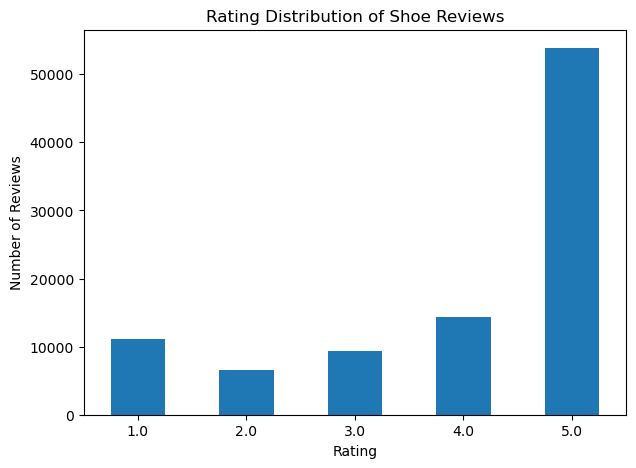

In [7]:
shoe_review_rows = []

for review in read_jsonl_gz(review_path):
    if review.get("parent_asin") in shoe_asins:
        shoe_review_rows.append({
            "rating": review.get("rating"),
            "title": review.get("title"),
            "text": review.get("text"),
            "parent_asin": review.get("parent_asin"),
        })

shoe_reviews_df = pd.DataFrame(shoe_review_rows)
print("연결된 전체 리뷰 수:", len(shoe_reviews_df))

shoe_reviews_df = shoe_reviews_df.dropna(subset=["text", "rating"])
shoe_reviews_df = shoe_reviews_df.loc[
    shoe_reviews_df["text"].str.strip().ne("")
].reset_index(drop=True)

print("정리 후 리뷰 수:", len(shoe_reviews_df))
display(shoe_reviews_df.head())

rating_counts = shoe_reviews_df["rating"].value_counts().sort_index()
rating_distribution = pd.DataFrame({
    "count": rating_counts,
    "percent": (100 * rating_counts / len(shoe_reviews_df)).round(2),
})
display(rating_distribution)

rating_counts.plot.bar(figsize=(7, 5), rot=0)
plt.title("Rating Distribution of Shoe Reviews")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

In [8]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

train_idx, test_idx = next(
    sgkf.split(
        X=shoe_reviews_df,
        y=shoe_reviews_df["rating"],
        groups=shoe_reviews_df["parent_asin"],
    )
)

shoe_train_df = shoe_reviews_df.iloc[train_idx].copy()
shoe_test_df = shoe_reviews_df.iloc[test_idx].copy()

# 원본 리뷰의 행 번호를 보존해 나중에 문장을 리뷰에 다시 연결한다.
shoe_train_df.index.name = "review_id"
shoe_test_df.index.name = "review_id"
shoe_train_df = shoe_train_df.reset_index()
shoe_test_df = shoe_test_df.reset_index()

overlap = set(shoe_train_df["parent_asin"]) & set(shoe_test_df["parent_asin"])

print("Train 리뷰 수:", len(shoe_train_df))
print("Test 리뷰 수:", len(shoe_test_df))
print("Train 상품 수:", shoe_train_df["parent_asin"].nunique())
print("Test 상품 수:", shoe_test_df["parent_asin"].nunique())
print("양쪽에 겹치는 상품 수:", len(overlap))

display(pd.DataFrame({
    "train_percent": shoe_train_df["rating"].value_counts(normalize=True),
    "test_percent": shoe_test_df["rating"].value_counts(normalize=True),
}).sort_index().mul(100).round(2))

assert not overlap

Train 리뷰 수: 76320
Test 리뷰 수: 19080
Train 상품 수: 34721
Test 상품 수: 8674
양쪽에 겹치는 상품 수: 0


,train_percent,test_percent
rating,,
1.0,11.72,11.72
2.0,6.93,6.92
3.0,9.87,9.87
4.0,15.04,15.04
5.0,56.44,56.44


In [9]:
import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt", quiet=True, raise_on_error=True)
nltk.download("punkt_tab", quiet=True, raise_on_error=True)

pilot_df = shoe_train_df.sample(
    n=min(2000, len(shoe_train_df)),
    random_state=42,
).reset_index(drop=True)

sentence_rows = []

for row in pilot_df.itertuples(index=False):
    for sentence in sent_tokenize(row.text, language="english"):
        sentence = sentence.strip()
        word_count = len(sentence.split())

        if 3 <= word_count <= 60:
            sentence_rows.append({
                "review_id": row.review_id,
                "parent_asin": row.parent_asin,
                "sentence": sentence,
            })

sentence_df = (
    pd.DataFrame(sentence_rows)
    .drop_duplicates(subset="sentence")
    .reset_index(drop=True)
)

print("파일럿 리뷰 수:", len(pilot_df))
print("필터링·중복 제거 후 문장 수:", len(sentence_df))
display(sentence_df.head(20))

파일럿 리뷰 수: 2000
필터링·중복 제거 후 문장 수: 4489


,review_id,parent_asin,sentence
0,81201,B07D8J2FJR,The shoes were fairly comfortable.
1,81201,B07D8J2FJR,You want to measure your feet and buy a pair b...
2,51068,B087LWQGWM,Made blisters on my granddaughters foot
3,67360,B073GS7S8J,Not even close to what it looks like on the pi...
4,67360,B073GS7S8J,Very disappointed with this product!
5,32304,B00J2HY6ZC,"Very comfortable slippers,"
6,9624,B07T1VVW79,Perfect shoes for me!
7,9624,B07T1VVW79,"My style, and they are so comfortable."
8,9624,B07T1VVW79,I usually have blisters after wearing new shoe...
9,9624,B07T1VVW79,"Cute, comfy and stylish."


In [10]:
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

sentences = sentence_df["sentence"].tolist()

embeddings = sbert.encode(
    sentences,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)

print("SBERT 임베딩 크기:", embeddings.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/71 [00:00<?, ?it/s]

SBERT 임베딩 크기: (4489, 768)


In [11]:
from umap import UMAP

umap_model = UMAP(
    n_neighbors=15,
    n_components=10,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)

reduced_embeddings = umap_model.fit_transform(embeddings)

print("축소 전:", embeddings.shape)
print("축소 후:", reduced_embeddings.shape)

C:\Users\lkl04\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\lkl04\anaconda3\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


축소 전: (4489, 768)
축소 후: (4489, 10)


In [12]:
import hdbscan

hdbscan_model = hdbscan.HDBSCAN(
    min_cluster_size=30,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)

sentence_df["cluster"] = hdbscan_model.fit_predict(reduced_embeddings)
sentence_df["cluster_prob"] = hdbscan_model.probabilities_

noise_mask = sentence_df["cluster"].eq(-1)
valid_sentences = sentence_df.loc[~noise_mask]

print("군집 수:", valid_sentences["cluster"].nunique())
print("노이즈 문장 수:", int(noise_mask.sum()))
print(f"노이즈 비율: {noise_mask.mean():.2%}")

cluster_summary = (
    valid_sentences.groupby("cluster")
    .agg(
        sentence_count=("sentence", "size"),
        avg_probability=("cluster_prob", "mean"),
    )
    .sort_values("sentence_count", ascending=False)
)

display(cluster_summary)

군집 수: 30
노이즈 문장 수: 1370
노이즈 비율: 30.52%


,sentence_count,avg_probability
cluster,,
3,260,0.500857
14,217,0.989019
19,211,0.946733
29,199,0.720523
18,197,0.980108
20,188,0.720549
24,170,0.686637
8,150,0.936254
26,139,0.745781


In [13]:
valid_cluster_ids = sorted(valid_sentences["cluster"].unique())

for cluster_id in valid_cluster_ids:
    cluster_data = (
        sentence_df.loc[sentence_df["cluster"].eq(cluster_id)]
        .sort_values("cluster_prob", ascending=False)
    )

    print(f"\n{'=' * 70}")
    print(f"CLUSTER {cluster_id} | 문장 수 = {len(cluster_data)}")
    print("=" * 70)

    for sentence in cluster_data["sentence"].head(10):
        print("-", sentence)


CLUSTER 0 | 문장 수 = 32
- What can I say?
- They are attention pieces where ever I go.
- All the girls at work love them and even the men commented on how nice they are!
- I get lots of compliments whenever I wear them.
- I always receive a compliment or 2 when I were them.
- I get so many compliments on these.
- I wear these often and get compliments.
- I got so many compliments!
- I received so many compliments on these.
- My GF was thrilled and received numerous compliments from other pretty ladies!

CLUSTER 1 | 문장 수 = 78
- I have just about every color...well, almost every.
- I might get them in a few colors!
- I got the light taupe, and it's different, which I like.
- I order in black and brown
- I bought the black scarlet and they are BEAUTIFUL - my husband even likes them!
- I got the grey and I'm glad I did they look nice.
- I want them in every color available.
- (I own black and grey already.)
- I even ordered another color, same style.
- Wish I could get it in White!

CLUSTER

In [14]:
cluster_to_aspect = {
    0: "None",
    1: "디자인",
    2: "디자인",
    3: "None",
    4: "디자인",
    5: "None",
    6: "배송",
    7: "착화감",
    8: "착화감",
    9: "반품/교환",
    10: "내구성",
    11: "사진-실물 일치",
    12: "기능",
    13: "가격/가성비",
    14: "None",
    15: "None",
    16: "None",
    17: "기능",
    18: "사이즈/핏",
    19: "사이즈/핏",
    20: "사이즈/핏",
    21: "사이즈/핏",
    22: "사이즈/핏",
    23: "사이즈/핏",
    24: "None",
    25: "내구성",
    26: "기능",
    27: "착화감",
    28: "None",
    29: "None",
}

display(pd.Series(cluster_to_aspect, name="aspect").value_counts())

aspect
None        9
사이즈/핏       6
디자인         3
착화감         3
기능          3
내구성         2
배송          1
반품/교환       1
사진-실물 일치    1
가격/가성비      1
Name: count, dtype: int64

### 군집마다 768차원 대표 벡터 계산 (noise(-1) 문장은 제외)

In [15]:
import numpy as np

# In [11]의 embeddings와 현재 sentence_df의 행 순서를 확인
if sentence_df["sentence"].tolist() != sentences:
    raise ValueError("sentence_df의 문장 순서가 SBERT 임베딩 생성 당시와 다릅니다.")

if embeddings.shape != (len(sentence_df), 768):
    raise ValueError(f"문장 수와 임베딩 크기를 확인하세요: {embeddings.shape}")

labels = sentence_df["cluster"].to_numpy()
cluster_ids = np.unique(labels[labels != -1])

if set(cluster_ids) != set(cluster_to_aspect):
    raise ValueError("현재 HDBSCAN 군집 번호와 aspect 대응표의 번호가 다릅니다.")

# 대표 벡터 배열의 i번째 행은 cluster_ids[i]에 대응
mean_vectors = np.stack([
    embeddings[labels == cluster_id].mean(axis=0)
    for cluster_id in cluster_ids
])

norms = np.linalg.norm(mean_vectors, axis=1, keepdims=True)
if not np.isfinite(norms).all() or (norms == 0).any():
    raise ValueError("정규화할 수 없는 대표 벡터가 있습니다.")

cluster_centroids = mean_vectors / norms

centroid_info = pd.DataFrame({
    "cluster": cluster_ids,
    "aspect": [cluster_to_aspect[c] for c in cluster_ids],
    "sentence_count": [int((labels == c).sum()) for c in cluster_ids],
})

print("대표 벡터 크기:", cluster_centroids.shape)
print("대표 벡터 계산에 사용한 문장 수:", centroid_info["sentence_count"].sum())
display(centroid_info)

대표 벡터 크기: (30, 768)
대표 벡터 계산에 사용한 문장 수: 3119


,cluster,aspect,sentence_count
0,0,None,32
1,1,디자인,78
2,2,디자인,31
3,3,None,260
4,4,디자인,119
5,5,None,47
6,6,배송,33
7,7,착화감,67
8,8,착화감,150
9,9,반품/교환,74


### 파일럿 밖의 실제 리뷰에 aspect 후보 배정-학습 리뷰 100개로 먼저 확인

In [16]:
from nltk.tokenize import sent_tokenize

# 1. 군집을 만들 때 사용하지 않은 학습 리뷰에서 표본 추출
remaining_train = shoe_train_df.loc[
    ~shoe_train_df["review_id"].isin(pilot_df["review_id"])
]

check_reviews = remaining_train.sample(
    n=min(100, len(remaining_train)),
    random_state=42,
)

# 2. 리뷰를 문장으로 나누되 원래 리뷰 ID와 문장 순서를 보관
rows = []

for review in check_reviews.itertuples(index=False):
    review_sentences = sent_tokenize(review.text, language="english")

    for sentence_no, sentence in enumerate(review_sentences, start=1):
        sentence = sentence.strip()

        if 3 <= len(sentence.split()) <= 60:
            rows.append({
                "review_id": review.review_id,
                "sentence_no": sentence_no,
                "sentence": sentence,
            })

check_df = pd.DataFrame(rows)

if check_df.empty:
    raise ValueError("표본에서 3~60단어 조건을 만족하는 문장이 없습니다.")

# 3. In [11]과 같은 모델·정규화 방식으로 새 문장 임베딩
check_embeddings = sbert.encode(
    check_df["sentence"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True,
)

# 4. 각 문장과 30개 대표 벡터의 코사인 유사도 계산
# 양쪽 벡터를 모두 정규화했으므로 내적이 코사인 유사도와 같음
similarities = check_embeddings @ cluster_centroids.T
nearest_rows = similarities.argmax(axis=1)

check_df["nearest_cluster"] = cluster_ids[nearest_rows]
check_df["cosine_similarity"] = similarities[
    np.arange(len(check_df)), nearest_rows
]
check_df["aspect_candidate"] = check_df["nearest_cluster"].map(cluster_to_aspect)

# 5. 같은 리뷰의 문장들을 붙여서 확인
check_df = check_df.sort_values(
    ["review_id", "sentence_no"]
).reset_index(drop=True)

print("뽑은 리뷰 수:", len(check_reviews))
print("길이 조건을 통과한 문장이 있는 리뷰 수:", check_df["review_id"].nunique())
print("aspect 후보를 계산한 문장 수:", len(check_df))

with pd.option_context("display.max_colwidth", None):
    display(check_df.head(30).round({"cosine_similarity": 3}))

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

뽑은 리뷰 수: 100
길이 조건을 통과한 문장이 있는 리뷰 수: 92
aspect 후보를 계산한 문장 수: 229


,review_id,sentence_no,sentence,nearest_cluster,cosine_similarity,aspect_candidate
0,821,1,These shoes are ok.,28,0.783,None
1,821,2,"Wore out really fast, my daughter already has holes in the toe area.",25,0.684,내구성
2,1517,1,They were adorable and my daughter loved them.,3,0.785,None
3,2092,1,keep feet nice and warm easy to put on and take off,26,0.784,기능
4,4257,1,great for the pool and sturdy toe are to protect the toes,26,0.649,기능
5,5260,1,Very cute but the calf part of the butt is very undersized I have chicken legs and they wouldn’t zip order in wide calf if your not 120 lbs I’m 5”6 size 16,18,0.512,사이즈/핏
6,6397,1,I ordered my size 8 1/2 and they are Large.,20,0.760,사이즈/핏
7,6397,3,The shoe is good quality.,28,0.768,None
8,6397,4,Looks just as pictured.,11,0.682,사진-실물 일치
9,6397,6,I really wanted to love this shoe but they are just too big.,18,0.738,사이즈/핏


In [17]:
COSINE_THRESHOLD = 0.60

def accepted_aspect_mask(frame):
    return (
        frame["cosine_similarity"].ge(COSINE_THRESHOLD)
        & frame["aspect_candidate"].notna()
        & frame["aspect_candidate"].ne("None")
    )

check_passed = check_df.loc[accepted_aspect_mask(check_df)].copy()

print(f"표본 리뷰: {len(check_reviews):,}개")
print(f"길이 조건을 통과한 문장: {len(check_df):,}개")
print(f"최종 aspect가 배정된 문장: {len(check_passed):,}개")
print(f"aspect가 하나 이상 배정된 리뷰: {check_passed['review_id'].nunique():,}개")

# 채택된 문장 중 임계값에 가장 가까운 사례부터 확인
with pd.option_context("display.max_colwidth", None):
    display(
        check_passed.sort_values("cosine_similarity")
        [["review_id", "sentence", "aspect_candidate", "cosine_similarity"]]
        .head(15)
        .round({"cosine_similarity": 3})
    )

표본 리뷰: 100개
길이 조건을 통과한 문장: 229개
최종 aspect가 배정된 문장: 82개
aspect가 하나 이상 배정된 리뷰: 56개


,review_id,sentence,aspect_candidate,cosine_similarity
92,45200,Toes slide out of the front.,착화감,0.601
190,73272,(Less heel pain).,착화감,0.611
50,29127,***Take care of them and charge them properly***and these shoes will still function well past the point of outgrowing them.,내구성,0.612
209,83334,"They were easy to return, but I would suggest finding a different sandal.",내구성,0.612
207,83334,They broke within an hour of getting them.,반품/교환,0.615
166,70001,Returned right away.,반품/교환,0.620
119,56377,"It feels so comfortable, like walking on a cloud!",착화감,0.620
52,29207,"they are a little tough to get on because they don't really slide on, but are comfy.",착화감,0.623
168,71186,Lights didn’t work on one shoe!!,내구성,0.628
125,56428,"I thought I might have ordered wrong...but when the size 11 came for the second time, I knew it was that they didn’t send the right size (twice).",사이즈/핏,0.628


In [18]:
%pip install sentencepiece protobuf

Note: you may need to restart the kernel to use updated packages.


In [22]:
import subprocess
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

absa_temp = TemporaryDirectory()
absa_dir = Path(absa_temp.name)
absa_tokenizer_dir = absa_dir / "tokenizer"

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--target",
     str(absa_dir / "deps"), "protobuf==7.36.1"],
    check=True,
)

convert_tokenizer = """
import sys
sys.path.insert(0, sys.argv[1])

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "yangheng/deberta-v3-base-absa-v1.1"
)
tokenizer.save_pretrained(sys.argv[2])
"""

subprocess.run(
    [sys.executable, "-c", convert_tokenizer,
     str(absa_dir / "deps"), str(absa_tokenizer_dir)],
    check=True,
)

assert (absa_tokenizer_dir / "tokenizer.json").is_file()
print("ABSA 토크나이저 준비 완료")

ABSA 토크나이저 준비 완료


In [24]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ASPECT_EN = {
    "디자인": "design",
    "배송": "delivery",
    "착화감": "comfort",
    "반품/교환": "returns and exchanges",
    "내구성": "durability",
    "사진-실물 일치": "match with product photos",
    "기능": "functionality",
    "가격/가성비": "value for money",
    "사이즈/핏": "size and fit",
}
SENTIMENTS = ["positive", "negative", "neutral"]

assert set(ASPECT_EN) == set(cluster_to_aspect.values()) - {"None"}

model_name = "yangheng/deberta-v3-base-absa-v1.1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(str(absa_tokenizer_dir))
sentiment_model = AutoModelForSequenceClassification.from_pretrained(model_name)
sentiment_model = sentiment_model.to(device).eval()

id_to_label = {
    int(i): label.lower()
    for i, label in sentiment_model.config.id2label.items()
}
assert set(id_to_label.values()) == set(SENTIMENTS), id_to_label
print("감성 모델 실행 장치:", device)

@torch.inference_mode()
def predict_sentiments(frame, batch_size=32):
    labels = []
    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start:start + batch_size]
        targets = [ASPECT_EN[a] for a in batch["aspect_candidate"]]

        inputs = tokenizer(
            batch["sentence"].tolist(),
            text_pair=targets,
            padding=True,
            truncation="only_first",
            max_length=256,
            return_tensors="pt",
        ).to(device)

        logits = sentiment_model(**inputs).logits
        predicted_ids = logits.argmax(dim=1).cpu().tolist()
        labels.extend(id_to_label[i] for i in predicted_ids)

    return labels

check_passed["sentiment"] = predict_sentiments(check_passed)

with pd.option_context("display.max_colwidth", None):
    display(
        check_passed[
            ["review_id", "sentence", "aspect_candidate",
             "cosine_similarity", "sentiment"]
        ].head(20)
    )

C:\Users\lkl04\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lkl04\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Users\lkl04\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lkl04\.cache\huggingface\hub\models--yangheng--deberta-v3-base-absa-v1.1. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

감성 모델 실행 장치: cpu


,review_id,sentence,aspect_candidate,cosine_similarity,sentiment
1,821,"Wore out really fast, my daughter already has holes in the toe area.",내구성,0.683913,negative
3,2092,keep feet nice and warm easy to put on and take off,기능,0.784202,positive
4,4257,great for the pool and sturdy toe are to protect the toes,기능,0.648840,positive
6,6397,I ordered my size 8 1/2 and they are Large.,사이즈/핏,0.760360,negative
8,6397,Looks just as pictured.,사진-실물 일치,0.681865,positive
9,6397,I really wanted to love this shoe but they are just too big.,사이즈/핏,0.738490,negative
10,6397,I should have got a half size down.,사이즈/핏,0.693693,negative
16,7496,They need longer Velcro on the straps.,기능,0.677001,negative
19,9124,As other reviewers have said they run small.,사이즈/핏,0.745524,positive
20,9124,I generally wear a 9.5-10 so I ordered the 10-11 and they fit perfectly.,사이즈/핏,0.819436,positive


In [26]:
from pathlib import Path
from tempfile import TemporaryDirectory
from importlib.metadata import version
from datetime import datetime
import json
import shutil
import numpy as np

assert "sentiment" in check_passed.columns
assert cluster_centroids.shape == (len(cluster_ids), 768)
assert shoe_train_df["review_id"].is_unique
assert shoe_test_df["review_id"].is_unique

# 다시 실행해도 이전 ZIP과 구분되도록 이름에 시각을 넣는다.
bundle_id = datetime.now().strftime("shoe_absa_%Y%m%d_%H%M%S")
zip_base = Path.cwd() / bundle_id

with TemporaryDirectory() as tmp:
    root = Path(tmp)

    # CSV를 압축해 Windows Jupyter와 Colab 사이에서 읽기 쉽게 저장한다.
    for name, frame in {
        "train": shoe_train_df,
        "test": shoe_test_df,
        "check_reviews": check_reviews,
        "check_df": check_df,
        "check_passed": check_passed,
    }.items():
        frame.to_csv(root / f"{name}.csv.gz", index=False, compression="gzip")

    np.savez(
        root / "clusters.npz",
        cluster_ids=cluster_ids,
        cluster_centroids=cluster_centroids,
    )

    settings = {
        "bundle_id": bundle_id,
        "threshold": float(COSINE_THRESHOLD),
        "cluster_to_aspect": {str(k): v for k, v in cluster_to_aspect.items()},
        "aspect_en": ASPECT_EN,
        "sentiments": SENTIMENTS,
        "train_count": len(shoe_train_df),
        "test_count": len(shoe_test_df),
        "check_passed_count": len(check_passed),
    }
    (root / "settings.json").write_text(
        json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    # Colab에서도 모델을 읽는 라이브러리 버전을 맞춘다.
    packages = ["sentence-transformers", "transformers", "tokenizers", "nltk"]
    (root / "requirements.txt").write_text(
        "\n".join(f"{p}=={version(p)}" for p in packages),
        encoding="utf-8",
    )

    # 현재 메모리에 로드된 실제 모델과 성공한 토크나이저를 저장한다.
    sbert.save(str(root / "sbert"))
    sentiment_model.save_pretrained(root / "absa")
    tokenizer.save_pretrained(root / "absa")
    assert (root / "absa" / "tokenizer.json").is_file()

    zip_path = Path(shutil.make_archive(str(zip_base), "zip", root_dir=root))

print("Google Drive에 올릴 파일:", zip_path.resolve())
print(f"ZIP 크기: {zip_path.stat().st_size / 1024**3:.2f} GiB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Google Drive에 올릴 파일: D:\1. 연구, 프로젝트\3. 비정형 term project\shoe_absa_20261123_094430.zip
ZIP 크기: 0.97 GiB
